
# Diabetic Retinopathy Detection Using Deep Learning and MLOps

**Student name:** MILDRED EWENRIM EBOMAH

**Course:** Machine Learning Pipeline (MLOps)

**Submission date:** 26th November, 2026

**GitHub:** https://github.com/MEE-DRED/MLOPs.git

**Google Drive:** https://drive.google.com/drive/folders/1N88fRtnIaKBlSz78B3uExd5efw9eQ3vO?usp=sharing

**Video Presentation:** 

---

## 1. Introduction

**Overview**

This project is an extension of the summative project from the Introduction to Machine Learning module.

**Extension of Previous Project**

Whereas the previous project focused on tabular data from healthcare, this project uses non-tabular data from healthcare. Specifically, retinal fundus images have been analysed to detect different severities of diabetic retinopathy. Diabetic retinopathy is an eye condition caused by diabetes. If it is not detected and treated correctly it can lead to visual impairment and blindness.

**Implementation**

A deep learning model was trained to detect 5 levels of severity of diabetic retinopathy from retinal fundus images. A MobileNetV2 was used as a base model (transfer learning).

An end-to-end Machine Learning Operations (MLOps) pipeline was also implemented. This means that in addition to developing and evaluating the model, the model can be used in an API. An application has also been created so that users can interact with the model. Within the MLOps pipeline the model can also be monitored, tested, and retrained as data is uploaded.

**Summary**

This project combines image classification and MLOps. As such it demonstrates that a machine learning solution can be developed, evaluated, deployed and maintained.

## 2. Problem Statement

Diabetic retinopathy is a diabetes-related complication that affects the blood vessels of the retina. Assessing its severity involves examining retinal fundus images and identifying changes associated with different stages of the condition.

This project addresses the problem of automatically classifying retinal fundus images into five diabetic retinopathy severity grades using deep learning.

In addition to developing a classification model, there is a need to demonstrate how such a model can be operationalised beyond the training environment. This includes making predictions accessible through an API, monitoring model performance, handling new image data and supporting model retraining as additional data becomes available.

The central problem addressed by this project is therefore:

**How can a deep learning model be developed and deployed as an end-to-end MLOps pipeline to classify diabetic retinopathy severity from retinal fundus images, while supporting prediction, performance monitoring and retraining?**

## 3. Objectives

The main objective of this project is to develop and deploy an image-based diabetic retinopathy classification model through an end-to-end MLOps pipeline.

The specific objectives are to:

1. Acquire and validate a non-tabular healthcare dataset containing retinal fundus images and their corresponding diabetic retinopathy severity labels.
2. Perform exploratory data analysis and visualisations to understand the dataset, class distribution and relevant image characteristics.
3. Preprocess the images and prepare them for deep learning model development.
4. Develop and optimise a five-class image classification model using MobileNetV2 transfer learning.
5. Evaluate the model using appropriate classification metrics and analyse its performance and limitations.
6. Implement a prediction API that allows users to submit individual retinal images for classification.
7. Develop an application interface that provides model predictions, data visualisations and access to training and retraining functionalities.
8. Implement a retraining process that allows users to upload additional labelled images and trigger model retraining.
9. Deploy the solution on a cloud platform and assess its performance under different request loads and container configurations.

## 4. Running the Notebook

The notebook is designed to run in Google Colab with GPU acceleration.

To execute the notebook:

1. Open the notebook in Google Colab.
2. Navigate to **Runtime → Change runtime type** and select a GPU runtime (T4 GPU recommended).
3. Mount Google Drive when prompted to allow persistent storage of the dataset, trained models and generated outputs.
4. Ensure the project repository ZIP is available in the designated Google Drive project folder, or configure the GitHub repository URL in the setup section.
5. Ensure the RetinaMNIST dataset is available in the designated data directory. The notebook also supports downloading it through the MedMNIST package.
6. Run the notebook sequentially using **Runtime → Run all**.

The notebook imports the reusable modules from the project repository so that the preprocessing, model evaluation and model management processes remain consistent with the wider application.

**Storage:** Google Drive is used to retain generated models, experiment outputs, reports, checkpoints and retraining data across Colab sessions. If Google Drive is unavailable, temporary local storage is used, and generated files must be downloaded before the runtime is disconnected.

## 5. Notebook Outputs

Running the notebook produces the following outputs:

- Dataset validation results, including image dimensions, class distributions and duplicate-image checks.
- Exploratory visualisations showing the distribution of diabetic retinopathy grades and selected image characteristics.
- Preprocessed image data and training augmentation outputs.
- Model training histories and hyperparameter optimisation results.
- Model evaluation results, including accuracy, loss, precision, recall, F1-score, confusion matrix, ROC-AUC and quadratic weighted kappa.
- Classification reports and misclassification analysis.
- Model artefacts, metadata and version information saved to the project model registry.
- Individual image prediction results and model integrity checks.

The generated figures, tables and reports are saved in the project's output directories, while the trained model and its associated metadata are retained in the model registry for use by the API and retraining workflow.

## 6. Dataset description

This project uses **RetinaMNIST-224**, part of the **MedMNIST v2** collection. The dataset contains retinal fundus images labelled across five ordered diabetic-retinopathy severity grades. Images in this version have a size of **224 × 224 pixels** with three colour channels.

The official split sizes are shown below. The validation code in the next section checks the actual files rather than relying only on these expected values.

| Split | Number of images |
|---|---:|
| Training | 1,080 |
| Validation | 120 |
| Test | 400 |
| **Total** | **1,600** |

The original train, validation and test partitions are preserved. The training split is used to fit model weights; the validation split is used for early stopping and hyperparameter/model selection; and the test split is held out for final evaluation.

The five labels are ordinal: a prediction one grade away is less severe than a prediction several grades away. This is why the notebook reports both standard classification metrics and ordinal measures such as quadratic weighted kappa and within-one-grade accuracy.

**Dataset reference:** MedMNIST v2, described by Yang et al. in *Scientific Data* (2023). RetinaMNIST is derived from retinal fundus images associated with the DeepDRiD challenge.

## Imports and environment setup

In [1]:
# --- storage & code location ------------------------------------------------------
import os, sys, json, platform, zipfile, subprocess
from pathlib import Path

USE_DRIVE = True                                   # persist outputs on Google Drive
ALLOW_CPU = False                                  # True = run without a GPU anyway (a full run then takes hours)
DRIVE_PROJECT_DIR = "/content/drive/MyDrive/DR_MLOps"
REPO_URL = ""                                      # e.g. "https://github.com/<you>/Diabetic-Retinopathy-MLOps.git"
IN_COLAB = "google.colab" in sys.modules

drive_ok = False
if IN_COLAB and USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        Path(DRIVE_PROJECT_DIR).mkdir(parents=True, exist_ok=True)
        drive_ok = True
    except Exception as exc:                       # user declined / Drive unavailable
        print("Google Drive NOT available:", exc)

if drive_ok:
    PERSIST_DIR = Path(DRIVE_PROJECT_DIR)
elif IN_COLAB:
    PERSIST_DIR = Path("/content/dr_mlops_temporary")
    print("WARNING: using temporary Colab disk. Everything below is LOST when the runtime resets.")
else:
    PERSIST_DIR = Path(os.environ.get("DR_LOCAL_WORKDIR", "./dr_mlops_workdir")).resolve()
PERSIST_DIR.mkdir(parents=True, exist_ok=True)

# --- make the project's src/ package importable --------------------------------------
def find_repo_root():
    for c in (Path.cwd(), Path.cwd().parent):
        if (c / "src" / "config.py").exists():
            return c
    return None

repo = find_repo_root()
if repo is None:
    zip_path = PERSIST_DIR / "Diabetic-Retinopathy-MLOps.zip"
    code_dir = Path("/content/dr_code") if IN_COLAB else PERSIST_DIR / "code"
    if zip_path.exists():
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(code_dir)
    elif REPO_URL:
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(code_dir)], check=True)
    else:
        raise RuntimeError("Project code not found. Put Diabetic-Retinopathy-MLOps.zip in "
                           f"{PERSIST_DIR} or set REPO_URL above.")
    repo = next(p.parent.parent for p in code_dir.rglob("src/config.py"))
os.chdir(repo)
sys.path.insert(0, str(repo))

# config.py reads these at import time, so set them BEFORE importing src.config
os.environ.update({
    "DR_DATA_DIR": str(PERSIST_DIR / "data"),
    "DR_MODELS_DIR": str(PERSIST_DIR / "models"),
    "DR_OUTPUTS_DIR": str(PERSIST_DIR / "outputs"),
    "DR_DB_PATH": str(PERSIST_DIR / "database" / "dr_mlops.sqlite3"),
})
print("Code   :", repo)
print("Storage:", PERSIST_DIR, "(Google Drive)" if drive_ok else "(NOT persistent across sessions in Colab)")

Mounted at /content/drive
Code   : /content/dr_code/Diabetic-Retinopathy-MLOps (2)
Storage: /content/drive/MyDrive/DR_MLOps (Google Drive)


In [3]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import tensorflow as tf
    HAS_TF = True
except ImportError:                    # lets the data-only sections run without TensorFlow
    tf, HAS_TF = None, False

from src import config, visualization as viz
from src.data_acquisition import (ensure_dataset, load_retinamnist, validate_dataset,
                                  class_distribution_table, file_sha256)
from src.image_analysis import features_dataframe, FEATURE_EXPLANATIONS
from src.preprocessing import (load_image, validate_label, to_model_input, InvalidImageError,
                               InvalidLabelError, mobilenet_v2_reference_scaling)
from src.evaluate import (compute_metrics, text_report, predict_probabilities, misclassified_indices,
                          model_integrity_check, evaluate_acceptance)
from src.model_registry import ModelRegistry, build_metadata

FIG, TAB, REP = config.FIGURES_DIR, config.TABLES_DIR, config.REPORTS_DIR
for d in (FIG, TAB, REP):
    d.mkdir(parents=True, exist_ok=True)

env = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__}
if HAS_TF:
    env.update(tensorflow=tf.__version__, keras=tf.keras.__version__,
               gpus=[g.name for g in tf.config.list_physical_devices("GPU")])
    if not env["gpus"]:
        gpu_list = subprocess.run("nvidia-smi -L", shell=True, capture_output=True, text=True).stdout.strip()
        msg = ("TensorFlow sees NO GPU, so training would take hours (a CPU run of this notebook took about 3 hours).\n"
               f"nvidia-smi says: {gpu_list or 'no NVIDIA GPU is attached to this runtime'}\n"
               "- If no GPU is attached: Runtime > Change runtime type > T4 GPU, then Runtime > Run all.\n"
               "- If a GPU IS listed but TensorFlow cannot use it: run  !pip install -q 'tensorflow[and-cuda]'  then "
               "Runtime > Restart session and Run all.\n"
               "- To continue on CPU anyway, set ALLOW_CPU = True in the setup cell.")
        if not ALLOW_CPU:
            raise RuntimeError(msg)
        print("WARNING:", msg)
else:
    print("TensorFlow is not installed here: data sections will run, model sections need Colab.")
print(json.dumps(env, indent=2))

{
  "python": "3.13.16",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "tensorflow": "2.21.0",
  "keras": "3.13.2",
  "gpus": [
    "/physical_device:GPU:0"
  ]
}


## 7. Dataset acquisition

The acquisition function looks for the expected RetinaMNIST-224 dataset in the project data directory and supported Drive/Colab locations. If it is not already available, it attempts to obtain the dataset through the MedMNIST package and the configured download route.

The function does not intentionally replace the requested dataset with a different dataset. If acquisition fails, it stops and reports where the expected file should be placed. The resolved file path and dataset hash are retained for reproducibility and provenance.

In [4]:
if IN_COLAB and not Path(config.DATASET_NPZ).exists():
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "medmnist"], check=False)   # official downloader

DATASET_PATH = ensure_dataset(
    config.DATASET_NPZ,
    search_paths=[Path("/content/retinamnist_224.npz"),
                  Path("/content/drive/MyDrive/retinamnist_224.npz"),
                  PERSIST_DIR / "retinamnist_224.npz"])
print("Dataset file:", DATASET_PATH, f"({DATASET_PATH.stat().st_size / 1e6:.0f} MB)")

Dataset found: /content/drive/MyDrive/DR_MLOps/data/retinamnist_224.npz
Dataset file: /content/drive/MyDrive/DR_MLOps/data/retinamnist_224.npz (128 MB)


## 8. Dataset validation

Before analysis or training, the notebook checks that the dataset contains the required splits and arrays, that images have the expected **224 × 224 × 3** shape and `uint8` pixel type, and that every image has one valid label in the range 0–4.

It also checks for blank images, duplicate images within a split and identical images shared across splits. Cross-split duplicates would create a risk of data leakage because the model could encounter the same image during training and evaluation.

**Result from the recorded run:** all three splits passed validation. There were no blank images, no duplicates within a split, no cross-split duplicates, and no blocking validation issues. The verified split sizes were 1,080 training images, 120 validation images and 400 test images.

In [5]:
data = load_retinamnist(DATASET_PATH)
report = validate_dataset(data)
print(json.dumps(report, indent=2))
assert report["ok"], f"Dataset problems: {report['issues']}"
print("\nSHA-256 of dataset file:", file_sha256(DATASET_PATH))

(X_train, y_train), (X_val, y_val), (X_test, y_test) = data["train"], data["val"], data["test"]
dist = class_distribution_table(data)
counts = dist.pivot(index="class", columns="split", values="count").loc[list(config.CLASS_NAMES), ["train", "val", "test"]]
counts.loc["TOTAL"] = counts.sum()
display(counts)

{
  "splits": {
    "train": {
      "n_images": 1080,
      "n_labels": 1080,
      "class_counts": [
        486,
        128,
        206,
        194,
        66
      ],
      "blank_images": 0,
      "duplicates_within_split": 0
    },
    "val": {
      "n_images": 120,
      "n_labels": 120,
      "class_counts": [
        54,
        12,
        28,
        20,
        6
      ],
      "blank_images": 0,
      "duplicates_within_split": 0
    },
    "test": {
      "n_images": 400,
      "n_labels": 400,
      "class_counts": [
        174,
        46,
        92,
        68,
        20
      ],
      "blank_images": 0,
      "duplicates_within_split": 0
    }
  },
  "cross_split_duplicates": {
    "train&val": 0,
    "train&test": 0,
    "val&test": 0
  },
  "issues": [],
  "warnings": [],
  "ok": true
}

SHA-256 of dataset file: 6d579682003c35c5de003fd46c43e9b6f9015ddf73a1e9dece78d962944c7604


split,train,val,test
class,,,
No DR,486,54,174
Mild,128,12,46
Moderate,206,28,92
Severe,194,20,68
Proliferative DR,66,6,20
TOTAL,1080,120,400


## 9. Exploratory data analysis

This section checks the dataset's size, image dimensions, data type and pixel range before model training. The images are stored as `uint8` values in the range 0–255. The training split occupies approximately **162.6 MB** in memory in this representation.

The model input pipeline converts data to `float32` in batches, rather than converting the entire dataset to a second full-size array at once. This helps control memory use during training.

In [6]:
summary = pd.DataFrame({
    "images": {s: len(data[s][1]) for s in data},
    "shape": {s: str(data[s][0].shape[1:]) for s in data},
    "dtype": {s: str(data[s][0].dtype) for s in data},
    "pixel min": {s: int(data[s][0].min()) for s in data},
    "pixel max": {s: int(data[s][0].max()) for s in data},
    "memory (MB)": {s: round(data[s][0].nbytes / 1e6, 1) for s in data},
})
display(summary)

,images,shape,dtype,pixel min,pixel max,memory (MB)
train,1080,"(224, 224, 3)",uint8,0,255,162.6
val,120,"(224, 224, 3)",uint8,0,255,18.1
test,400,"(224, 224, 3)",uint8,0,255,60.2


## 10. Image visualisations

### 10.1 Example images by class

The grid displays example retinal images from each of the five DR grades. It provides a visual check of the image data and illustrates why the task is challenging: differences between neighbouring severity grades can be subtle, and image quality and acquisition conditions vary.

The examples are illustrative. A visual inspection of a small number of images is not sufficient to establish clinical patterns or model performance.

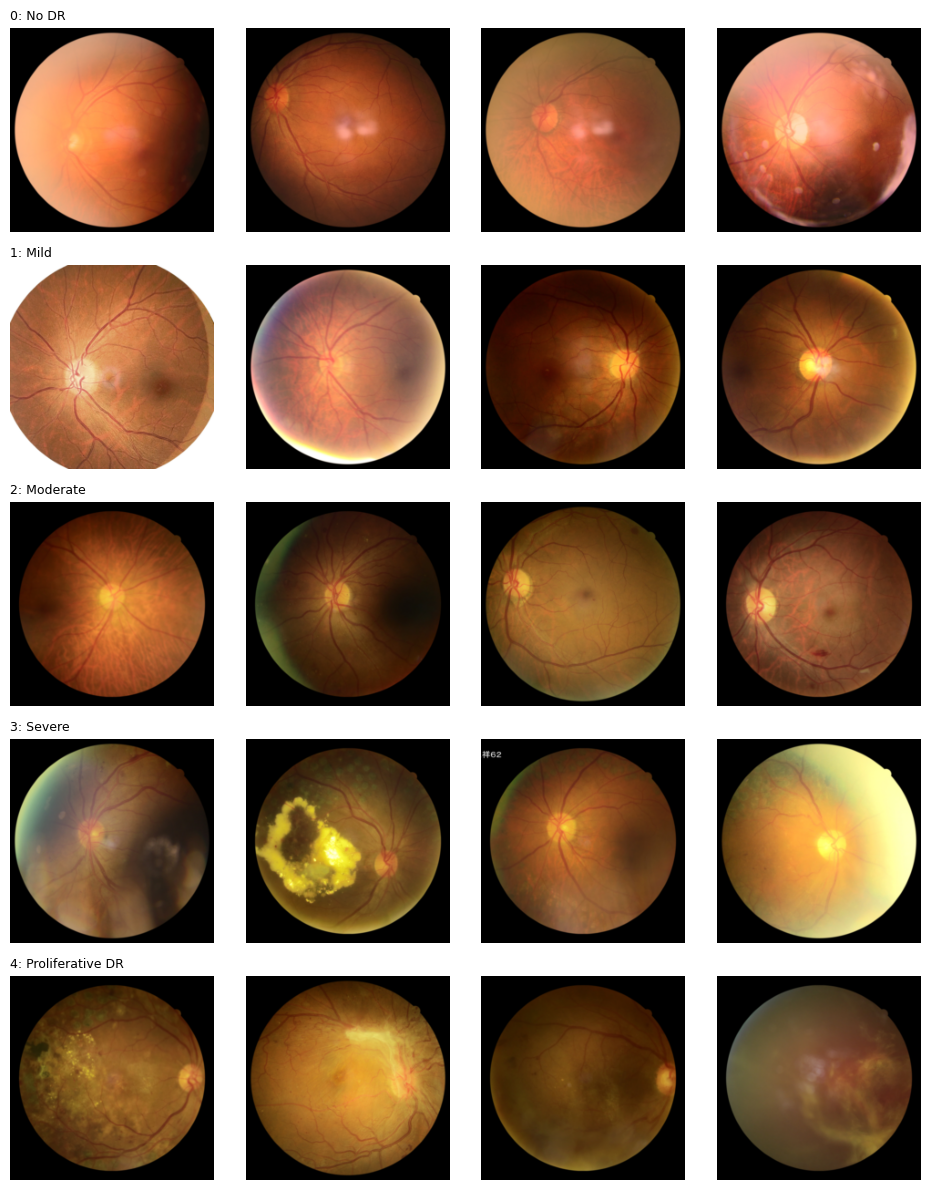

In [7]:
fig = viz.plot_sample_grid(X_train, y_train, per_class=4, save_path=FIG / "sample_images.png")
plt.show()

### 10.2 Image-derived characteristics

Four simple characteristics are calculated from each image. They describe image appearance and acquisition properties; they are **not direct measurements of disease severity**.

- **Brightness:** average pixel intensity within the retinal field.
- **Contrast:** variation in pixel intensity within the retinal field.
- **Sharpness:** variance of the Laplacian, used as a basic indicator of edge detail and focus. It can also increase with image noise.
- **Retina fraction:** the proportion of the image occupied by the detected retinal field rather than the surrounding dark area.

The black circular border is excluded when calculating brightness, contrast and sharpness. These measurements are used for exploratory analysis and a simple image-statistics baseline, not as a replacement for image-based classification.

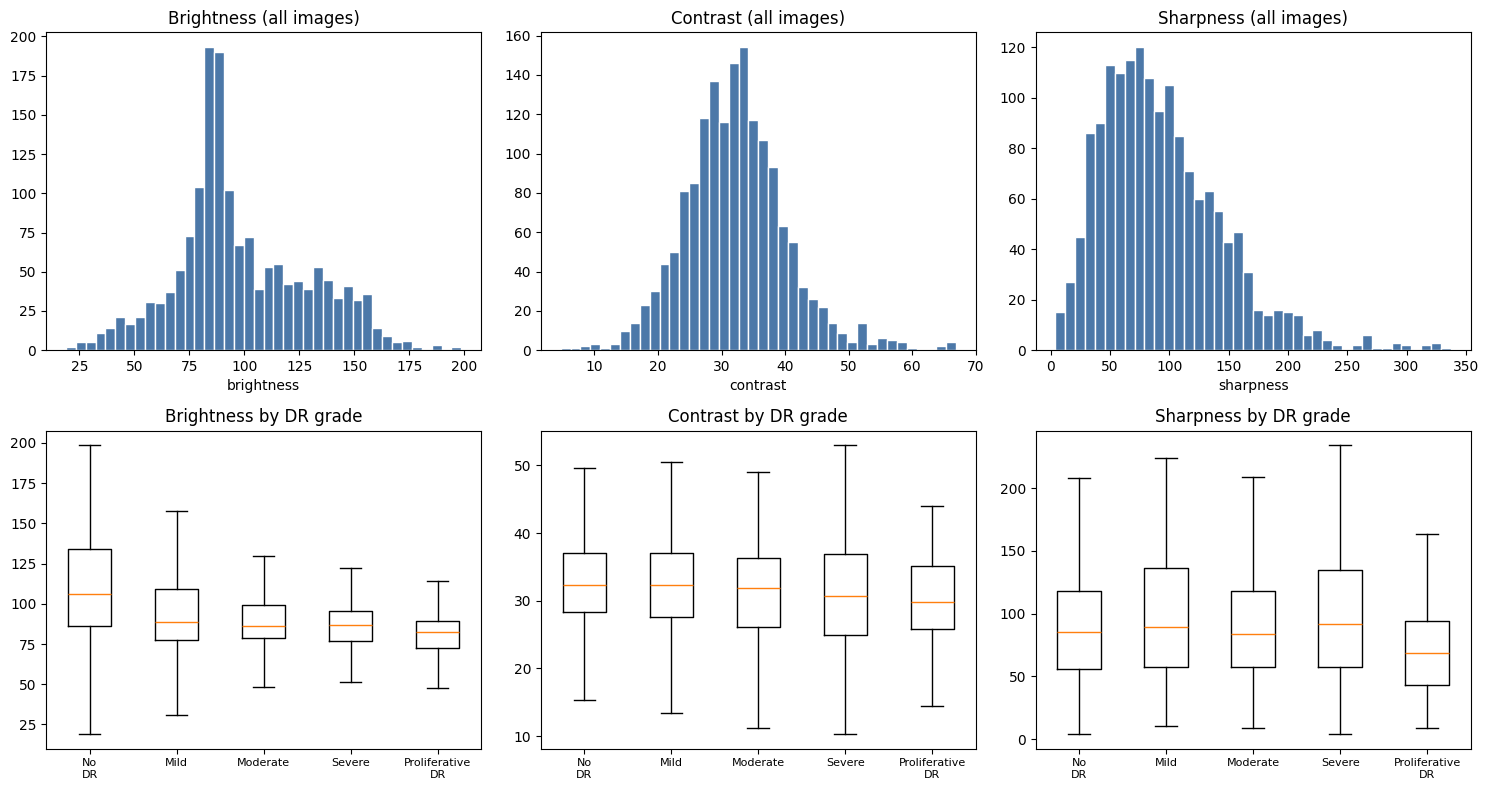

,brightness,contrast,sharpness,retina_fraction
class,,,,
No DR,106.23,32.36,85.11,0.72
Mild,88.46,32.37,89.05,0.72
Moderate,86.13,31.87,83.59,0.66
Severe,86.96,30.67,92.14,0.66
Proliferative DR,82.63,29.86,68.63,0.66


Spearman correlation of each characteristic with DR grade (0-4):


,rho
brightness,-0.323
contrast,-0.104
sharpness,-0.019
retina_fraction,-0.431


Median per split (splits should look alike):


,brightness,contrast,sharpness
split,,,
test,90.59,32.04,80.65
train,90.38,31.92,87.09
val,91.99,32.36,78.49


In [8]:
feat = features_dataframe(data, config.CLASS_NAMES)
feat.to_csv(TAB / "image_features.csv", index=False)

fig = viz.plot_feature_distributions(feat, save_path=FIG / "image_features.png")
plt.show()

order = list(config.CLASS_NAMES)
display(feat.groupby("class")[["brightness", "contrast", "sharpness", "retina_fraction"]].median().loc[order].round(2))
print("Spearman correlation of each characteristic with DR grade (0-4):")
display(feat[["brightness", "contrast", "sharpness", "retina_fraction"]].corrwith(feat["label"], method="spearman").round(3).to_frame("rho"))
print("Median per split (splits should look alike):")
display(feat.groupby("split")[["brightness", "contrast", "sharpness"]].median().round(2))

### Interpretation of the image characteristics

The recorded dataset summaries show different patterns across the four characteristics:

- **Brightness:** the median is 106.23 for No DR images and between 82.63 and 88.46 for the four DR grades. Its Spearman correlation with the ordered grade is **−0.323**. This is a noticeable association in this dataset, but it does not show that brightness causes or clinically indicates DR. Camera settings, exposure, clinic or other acquisition factors may contribute. It raises a shortcut-learning concern: a model could use image darkness as a proxy for the label.
- **Contrast:** class medians are relatively close, from 29.86 to 32.37, and the Spearman correlation is **−0.104**. Contrast has only a weak relationship with the label in this dataset.
- **Sharpness:** class medians vary, including a lower median for Proliferative DR, but the overall Spearman correlation is **−0.019**. Sharpness mainly describes focus and fine image detail; it does not show a meaningful monotonic relationship with grade here.
- **Retina fraction:** the median is 0.72 for No DR and Mild, and 0.66 for Moderate, Severe and Proliferative DR. Its Spearman correlation is **−0.431**, the strongest of the four simple characteristics. This suggests that image framing or field-of-view differences are associated with the labels and may act as a confounder.

The train, validation and test medians for brightness, contrast and sharpness are broadly similar, although sharpness varies between splits. These summaries do not rule out other forms of distribution shift.

**What this tells us:** image acquisition characteristics may carry information associated with the dataset labels. The classifier's performance must therefore be interpreted cautiously. Grad-CAM can help inspect model attention, but it cannot prove that the model bases its predictions on clinically meaningful retinal lesions.

### 10.3 Image-statistics-only baseline

To estimate how much label information is present in simple image characteristics, a balanced logistic-regression classifier is trained using only brightness, contrast, sharpness and retina fraction. It does not receive the retinal pixels and is not intended to be a competitive DR classifier.

The model is evaluated on the held-out test split. Its results provide a comparison point for the MobileNetV2 model and help reveal whether acquisition-related image characteristics may be associated with the labels.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

stat_cols = ["brightness", "contrast", "sharpness", "retina_fraction"]
f_tr, f_te = feat[feat.split == "train"], feat[feat.split == "test"]
stats_clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
stats_clf.fit(f_tr[stat_cols], f_tr["label"])
stats_baseline_test = compute_metrics(f_te["label"].values, stats_clf.predict_proba(f_te[stat_cols]))
display(pd.Series({k: stats_baseline_test[k] for k in ["accuracy", "f1_macro", "f1_weighted", "quadratic_weighted_kappa", "within_one_grade_accuracy"]}).round(3).to_frame("image-statistics-only baseline (test)"))
print("Accuracy of always predicting 'No DR':", round(stats_baseline_test["majority_class_baseline_accuracy"], 3))

,image-statistics-only baseline (test)
accuracy,0.365
f1_macro,0.260
f1_weighted,0.377
quadratic_weighted_kappa,0.343
within_one_grade_accuracy,0.665


Accuracy of always predicting 'No DR': 0.435


**Baseline interpretation:** on the test set, the image-statistics-only classifier achieved **36.5% accuracy** and **0.260 macro-F1**, compared with **43.5%** accuracy for always predicting the majority class (No DR). Its quadratic weighted kappa was **0.343** and within-one-grade accuracy was **66.5%**.

The statistics-only model is weaker than the final MobileNetV2 model, but it still carries some label information. This supports the need to investigate potential image-acquisition confounding rather than assuming that every learned signal comes from retinal lesions.

## 11. Class distribution

The dataset is imbalanced. In the training split, No DR accounts for **45.0%** of images, while Proliferative DR accounts for only **6.1%**. The same imbalance is visible in the validation and test splits.

This matters because a model can achieve a seemingly reasonable accuracy while performing poorly on less common grades. The training process therefore uses balanced class weights, model selection is based on validation macro-F1, and evaluation reports per-class precision, recall and F1 in addition to overall metrics.

The test split contains only **20 Proliferative DR images**, so estimates for that class have substantial uncertainty.

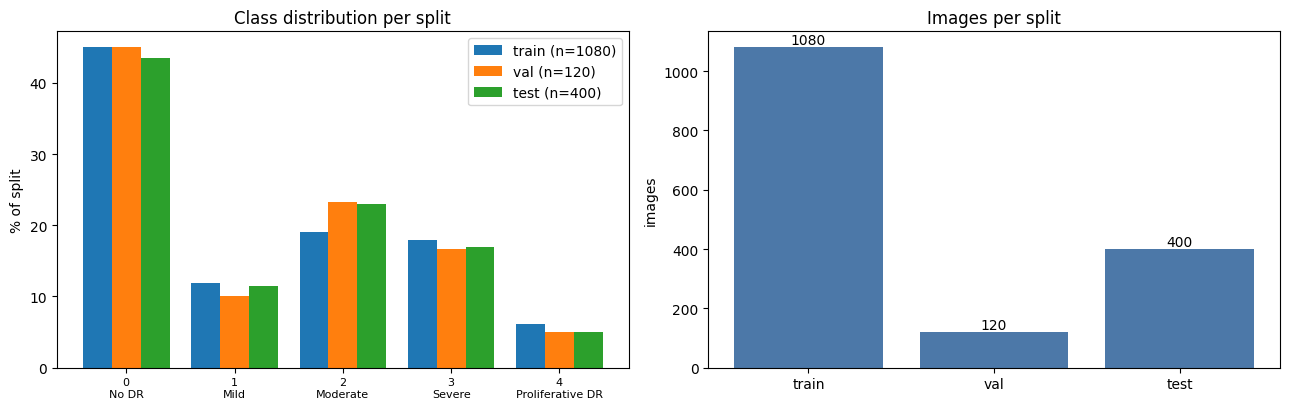

split,train,val,test
class,,,
No DR,45.0,45.0,43.5
Mild,11.8,10.0,11.5
Moderate,19.1,23.3,23.0
Severe,18.0,16.7,17.0
Proliferative DR,6.1,5.0,5.0


Majority-class accuracy on test (what 'always predict No DR' scores): 0.435


In [10]:
fig = viz.plot_class_distribution(data, save_path=FIG / "class_distribution.png")
plt.show()
display(dist.pivot(index="class", columns="split", values="percent").loc[order, ["train", "val", "test"]].round(1))
print("Majority-class accuracy on test (what 'always predict No DR' scores):",
      round(float(np.bincount(y_test).max() / len(y_test)), 3))

## 12. Image preprocessing

The project uses a shared preprocessing implementation in `src/preprocessing.py` so that uploaded images are prepared consistently for prediction and retraining.

1. **Validate the file:** accept JPEG and PNG files, verify that the content is readable, reject truncated or empty files, enforce a minimum image size and apply a file-size limit.
2. **Convert to RGB:** standardise accepted images to three colour channels.
3. **Fit to a square:** pad with black or apply the configured centre-crop option while preserving the image's aspect ratio.
4. **Resize:** produce a 224 × 224 image.
5. **Scale once:** the model contains a rescaling layer that maps pixel values from 0–255 to the range −1 to 1, as expected by MobileNetV2. Preprocessing outside the model supplies raw `float32` values in the 0–255 range.
6. **Validate labels:** supervised retraining labels must be whole numbers from 0 to 4.

The dataset images are already 224 × 224, so the image-format, validation and resizing steps are especially important for new files uploaded through the application. The following tests demonstrate both accepted input handling and rejection of invalid files and labels.

In [11]:
import io
from PIL import Image

def synthetic_png(size, mode="RGB", fmt="PNG"):
    buf = io.BytesIO(); Image.new(mode, size, (90, 40, 20) if mode == "RGB" else 90).save(buf, format=fmt); return buf.getvalue()

ok = load_image(synthetic_png((640, 480)))
print("640x480 PNG ->", ok.shape, ok.dtype, "| top-left pixel (padding):", ok[0, 0])

print("\nInvalid inputs are rejected with a clear message:")
bad = {"random text": b"not an image", "empty file": b"", "GIF (unsupported)": synthetic_png((64, 64), fmt="GIF"),
       "8x8 image (too small)": synthetic_png((8, 8)), "truncated PNG": synthetic_png((200, 200))[:-50]}
for name, blob in bad.items():
    try:
        load_image(blob); print(f"  {name:<24} ACCEPTED (unexpected!)")
    except InvalidImageError as exc:
        print(f"  {name:<24} rejected: {exc}")

print("\nLabel validation:")
for raw in [0, "3", 4, 5, -1, "abc", 1.5, None]:
    try:
        print(f"  {raw!r:<6} -> {validate_label(raw)}")
    except InvalidLabelError as exc:
        print(f"  {raw!r:<6} rejected: {exc}")

batch = to_model_input(X_val[:2])
print("\nModel input:", batch.shape, batch.dtype, "range", batch.min(), "-", batch.max(), "(raw 0-255; the model rescales internally)")
print("In-model scaling maps 0 / 127.5 / 255 to", mobilenet_v2_reference_scaling(np.array([0, 127.5, 255])))

640x480 PNG -> (224, 224, 3) uint8 | top-left pixel (padding): [0 0 0]

Invalid inputs are rejected with a clear message:
  random text              rejected: Not a readable image: cannot identify image file <_io.BytesIO object at 0x7ce62c3cbc40>
  empty file               rejected: Empty file
  GIF (unsupported)        rejected: Unsupported format GIF; allowed: ('JPEG', 'PNG')
  8x8 image (too small)    rejected: Image too small (8x8); minimum side 32px
  truncated PNG            rejected: Not a readable image: Truncated File Read

Label validation:
  0      -> 0
  '3'    -> 3
  4      -> 4
  5      rejected: Label 5 outside 0-4
  -1     rejected: Label -1 outside 0-4
  'abc'  rejected: Label must be an integer 0-4, got 'abc'
  1.5    rejected: Label must be a whole number, got 1.5
  None   rejected: Invalid label: None

Model input: (2, 224, 224, 3) float32 range 0.0 - 232.0 (raw 0-255; the model rescales internally)
In-model scaling maps 0 / 127.5 / 255 to [-1.  0.  1.]


## 13. Data augmentation

Data augmentation is included as Keras preprocessing layers in the model and is active only during training. Validation, test and prediction images are not randomly augmented.

The selected transformations are deliberately mild: horizontal flipping, small rotations, limited zoom, brightness adjustment and contrast adjustment. The intention is to expose the model to modest image variation without heavily distorting retinal structures.

Augmented images are transformed versions of existing training images. They do not increase the number of independent patients or independent source images and are not counted as new dataset observations.

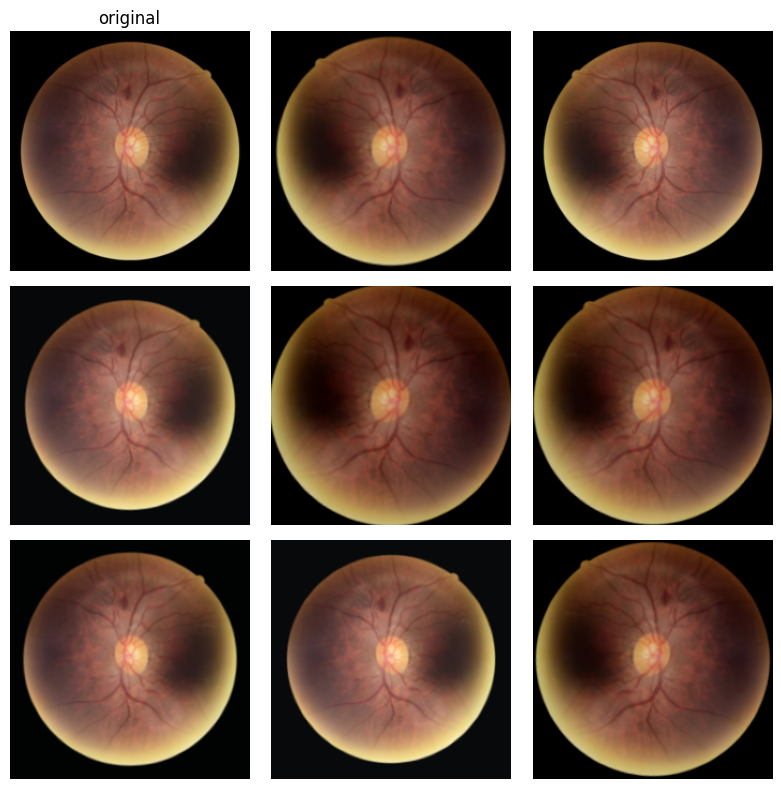

In [14]:
# [needs-tensorflow]
from src.preprocessing import build_augmentation
aug = build_augmentation(config.SEED)
sample = X_train[np.where(y_train == 2)[0][0]].astype("float32")
batch = np.repeat(sample[None], 8, axis=0)
assert np.allclose(aug(batch, training=False).numpy(), batch), "augmentation must be inactive at inference"
out = np.clip(aug(batch, training=True).numpy(), 0, 255).astype("uint8")
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
axes[0, 0].imshow(sample.astype("uint8")); axes[0, 0].set_title("original")
for ax, img in zip(axes.ravel()[1:], out):
    ax.imshow(img)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.savefig(FIG / "augmentation_examples.png", dpi=130); plt.show()

## 14. Train, validation and test separation

The dataset's original split is preserved:

| Split | Images | Purpose |
|---|---:|---|
| Training | 1,080 | Fit model weights, with augmentation and class weighting |
| Validation | 120 | Early stopping, hyperparameter selection and candidate-model acceptance |
| Test | 400 | Final evaluation after model selection |

The validation set is small, particularly for rare grades, so validation metrics and hyperparameter rankings can vary with a small number of predictions. The test set is kept separate from training and model selection to provide an independent final performance estimate for this run.

In [15]:
assert sum(report["cross_split_duplicates"].values()) == 0
for name, (x, y) in {"train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)}.items():
    print(f"{name:<5} {len(y):>5} images | class counts {np.bincount(y, minlength=5).tolist()}")

train  1080 images | class counts [486, 128, 206, 194, 66]
val     120 images | class counts [54, 12, 28, 20, 6]
test    400 images | class counts [174, 46, 92, 68, 20]


## 15. MobileNetV2 model architecture

The model follows this sequence:

```text
Input image (224 × 224 × 3; pixel range 0–255)
        ↓
Data augmentation (training only)
        ↓
Rescaling to [−1, 1]
        ↓
MobileNetV2 backbone (ImageNet weights; classification top removed)
        ↓
Global Average Pooling
        ↓
Dropout
        ↓
Dense layer with 5 softmax outputs
```

**Why MobileNetV2?** It provides a relatively lightweight convolutional backbone for transfer learning.

The recorded model has **2,264,389 total parameters**. Regularisation and overfitting controls include dropout, L2 regularisation on the classification layer, data augmentation, a frozen-backbone training stage, a lower learning rate during fine-tuning, and early stopping. The backbone uses ImageNet pretrained weights in the recorded run.

In [16]:
# [needs-tensorflow]
from src.model import build_model, set_backbone_trainable, compile_model
from src.train import (TrainConfig, set_seed, balanced_class_weights, make_datasets, run_stage1, run_stage2,
                       train_two_stage, search_hyperparameters, save_training_record)

set_seed(config.SEED)
BASE_CFG = TrainConfig()
print("Baseline training configuration:"); print(json.dumps(BASE_CFG.to_dict(), indent=2))

model, model_info = build_model(BASE_CFG.dropout, BASE_CFG.l2, weights="imagenet",
                                allow_weight_fallback=False, augment=True)
print(json.dumps(model_info, indent=2))
model.summary(show_trainable=False)

Baseline training configuration:
{
  "seed": 42,
  "dropout": 0.3,
  "l2": 0.0001,
  "batch_size": 32,
  "lr_head": 0.001,
  "lr_finetune": 0.0001,
  "epochs_head": 15,
  "epochs_finetune": 25,
  "unfreeze_layers": 40,
  "patience_head": 5,
  "patience_finetune": 8,
  "use_class_weights": true,
  "augment": true
}
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
{
  "architecture": "MobileNetV2 (alpha=1.0) + GAP + Dropout + Dense(softmax)",
  "pretrained_weights": "imagenet",
  "weight_fallback_used": false,
  "dropout": 0.3,
  "l2": 0.0001
}


Model: "dr_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_v2_scaling            │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_backbone            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 5)              │         6,405 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,264,389 (8.64 MB)

 Trainable params: 2,230,277 (8.51 MB)

 Non-trainable params: 34,112 (133.25 KB)

## 16. Transfer-learning strategy

Training is carried out in two stages.

- **Stage 1 – train the classification head:** the MobileNetV2 backbone is frozen and only the new classification head is trained. This adapts the final layer to the five DR grades while retaining the pretrained visual features.
- **Stage 2 – fine-tune the backbone:** the top 40 backbone layers are unfrozen and trained with a lower learning rate. Batch-normalisation layers remain frozen to reduce instability during fine-tuning.

The validation macro-F1 is used to compare the stages. If fine-tuning does not improve on the stage-1 result, the stage-1 checkpoint is retained.

In [17]:
# [needs-tensorflow]
stats = set_backbone_trainable(model, 0)
print("Stage-1 (frozen backbone):", stats)
stats = set_backbone_trainable(model, BASE_CFG.unfreeze_layers)
print("Stage-2 (top", BASE_CFG.unfreeze_layers, "layers unfrozen):", stats)
set_backbone_trainable(model, 0)   # back to stage-1 state

Stage-1 (frozen backbone): {'trainable_params': 6405, 'total_params': 2264389, 'frozen_params': 2257984, 'unfrozen_backbone_layers': 0}
Stage-2 (top 40 layers unfrozen): {'trainable_params': 1669765, 'total_params': 2264389, 'frozen_params': 594624, 'unfrozen_backbone_layers': 40}


{'trainable_params': 6405,
 'total_params': 2264389,
 'frozen_params': 2257984,
 'unfrozen_backbone_layers': 0}

## 17. Initial training: classification head

The first training stage establishes a baseline using the default training configuration. It uses the Adam optimiser, sparse categorical cross-entropy, a learning rate of 0.001, batch size 32 and balanced class weights, with a maximum of 15 epochs.

Early stopping and checkpointing monitor **validation macro-F1** rather than accuracy because the class distribution is imbalanced. The best checkpoint is restored when training stops. This baseline is then compared with fine-tuning and the hyperparameter-search candidates.

In [18]:
# [needs-tensorflow]
class_weights = balanced_class_weights(y_train)
print("Class weights:", {config.CLASS_NAMES[k]: round(v, 2) for k, v in class_weights.items()})

train_ds, val_ds = make_datasets((X_train, y_train), (X_val, y_val), BASE_CFG.batch_size, BASE_CFG.seed)
CKPT_DIR = PERSIST_DIR / "checkpoints" / "baseline"
t0 = time.time()
h1, best1, ckpt1, s1 = run_stage1(model, BASE_CFG, train_ds, val_ds, (X_val, y_val), class_weights, CKPT_DIR)
print(f"\nStage 1 done in {time.time() - t0:.0f}s | epochs run: {len(h1['loss'])} | best validation macro-F1: {best1:.4f}")

Class weights: {'No DR': 0.44, 'Mild': 1.69, 'Moderate': 1.05, 'Severe': 1.11, 'Proliferative DR': 3.27}
Epoch 1/15
34/34 - 18s - 522ms/step - accuracy: 0.3185 - loss: 1.6766 - val_accuracy: 0.5500 - val_loss: 1.2416 - val_macro_f1: 0.3985 - learning_rate: 0.0010
Epoch 2/15
34/34 - 4s - 112ms/step - accuracy: 0.4204 - loss: 1.3686 - val_accuracy: 0.5500 - val_loss: 1.1630 - val_macro_f1: 0.4633 - learning_rate: 0.0010
Epoch 3/15
34/34 - 5s - 139ms/step - accuracy: 0.4880 - loss: 1.3023 - val_accuracy: 0.5750 - val_loss: 1.1171 - val_macro_f1: 0.5084 - learning_rate: 0.0010
Epoch 4/15
34/34 - 3s - 81ms/step - accuracy: 0.4926 - loss: 1.2196 - val_accuracy: 0.5750 - val_loss: 1.1272 - val_macro_f1: 0.4919 - learning_rate: 0.0010
Epoch 5/15
34/34 - 3s - 78ms/step - accuracy: 0.5167 - loss: 1.1892 - val_accuracy: 0.5417 - val_loss: 1.1059 - val_macro_f1: 0.4791 - learning_rate: 0.0010
Epoch 6/15
34/34 - 4s - 120ms/step - accuracy: 0.5167 - loss: 1.1508 - val_accuracy: 0.6083 - val_loss: 0.

## 18. Fine-tuning the pretrained model

During stage 2, the top 40 MobileNetV2 layers are unfrozen and trained with a learning rate of 0.0001, which is lower than the classification-head learning rate. Early stopping uses a patience of eight epochs.

In the recorded baseline run, fine-tuning did not improve the best validation macro-F1 beyond the stage-1 checkpoint, so the stage-1 weights were retained for that baseline. The later hyperparameter search and final training run select and train their own configuration; their outcomes are reported separately below.

Epoch 1/25
34/34 - 17s - 508ms/step - accuracy: 0.4176 - loss: 1.4278 - val_accuracy: 0.4917 - val_loss: 1.1662 - val_macro_f1: 0.3738 - learning_rate: 1.0000e-04
Epoch 2/25
34/34 - 4s - 111ms/step - accuracy: 0.4620 - loss: 1.2741 - val_accuracy: 0.6167 - val_loss: 1.1544 - val_macro_f1: 0.5181 - learning_rate: 1.0000e-04
Epoch 3/25
34/34 - 3s - 90ms/step - accuracy: 0.5417 - loss: 1.1027 - val_accuracy: 0.5000 - val_loss: 1.2548 - val_macro_f1: 0.3999 - learning_rate: 1.0000e-04
Epoch 4/25
34/34 - 4s - 106ms/step - accuracy: 0.6009 - loss: 0.9815 - val_accuracy: 0.5083 - val_loss: 1.2792 - val_macro_f1: 0.4299 - learning_rate: 1.0000e-04
Epoch 5/25
34/34 - 3s - 100ms/step - accuracy: 0.6074 - loss: 0.9255 - val_accuracy: 0.5667 - val_loss: 1.0581 - val_macro_f1: 0.4417 - learning_rate: 5.0000e-05
Epoch 6/25
34/34 - 3s - 91ms/step - accuracy: 0.6583 - loss: 0.7805 - val_accuracy: 0.6333 - val_loss: 1.0854 - val_macro_f1: 0.5066 - learning_rate: 5.0000e-05
Epoch 7/25
34/34 - 3s - 90ms/

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 32 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Stage 2 done in 50s | epochs run: 10 | best validation macro-F1: 0.5625 | weights kept from stage 1


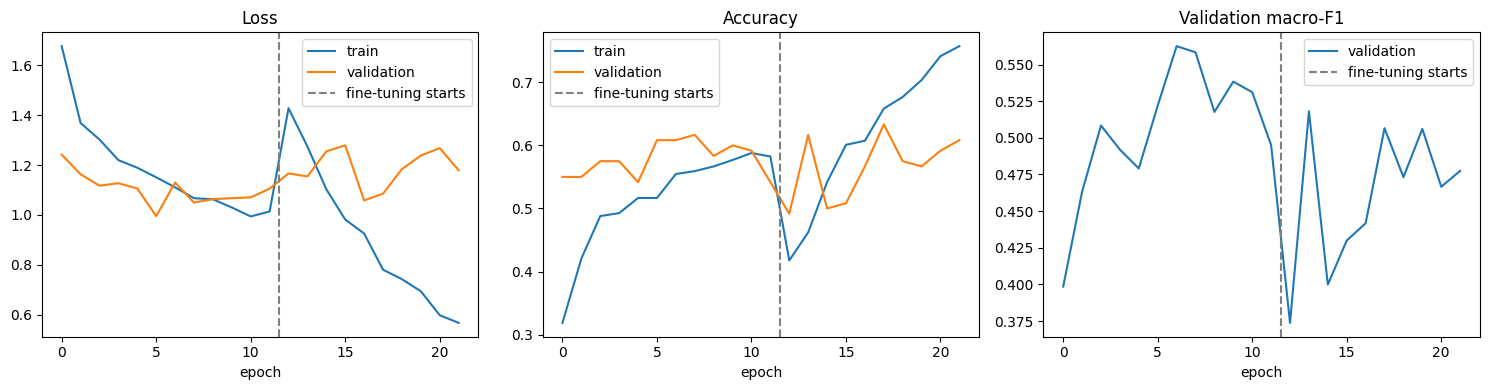

In [19]:
# [needs-tensorflow]
t0 = time.time()
h2, best_ft, chosen_stage, s2 = run_stage2(model, BASE_CFG, train_ds, val_ds, (X_val, y_val), class_weights,
                                           CKPT_DIR, best1, ckpt1)
baseline_history = {k: h1.get(k, []) + h2.get(k, []) for k in set(h1) | set(h2)}
baseline_val_f1 = best_ft
print(f"Stage 2 done in {time.time() - t0:.0f}s | epochs run: {len(h2['loss'])} | "
      f"best validation macro-F1: {best_ft:.4f} | weights kept from stage {chosen_stage}")
viz.plot_history(baseline_history, save_path=FIG / "baseline_training_curves.png"); plt.show()
del model                                   # free GPU memory before the search
import gc; gc.collect(); tf.keras.backend.clear_session()

## 19. Hyperparameter optimisation

A small random search is used instead of a large grid search because training resources are limited. Six trials, including the baseline configuration, compare combinations of:

| Hyperparameter | Values considered |
|---|---|
| Dropout | 0.2, 0.5 |
| Fine-tuning learning rate | 0.0001, 0.00003 |
| Batch size | 16, 32 |

Each trial uses a shortened training budget so that candidates can be compared within a practical runtime. Candidates are ranked by **validation macro-F1**. The best configuration is then trained again using the full epoch budget.

In the recorded search, the selected configuration achieved a validation macro-F1 of **0.5801** during the search. The selected settings were dropout 0.2, fine-tuning learning rate 0.0001 and batch size 32. Because the validation set contains only 120 images, small differences between trial scores should not be treated as conclusive evidence of superiority.

In [20]:
# [needs-tensorflow]
GRID = {"dropout": [0.2, 0.5], "lr_finetune": [1e-4, 3e-5], "batch_size": [16, 32]}
N_TRIALS = 6
t0 = time.time()
search_df = search_hyperparameters(BASE_CFG, (X_train, y_train), (X_val, y_val), GRID, N_TRIALS,
                                   trial_epochs=(5, 6), work_dir=PERSIST_DIR / "checkpoints" / "search")
print(f"Search finished in {time.time() - t0:.0f}s")
display(search_df.drop(columns="config").round(4))
search_df.drop(columns="config").to_csv(TAB / "hyperparameter_search.csv", index=False)
BEST_CFG = TrainConfig(**search_df.loc[0, "config"])
print("Selected configuration:", json.dumps(BEST_CFG.to_dict(), indent=2))

Restoring model weights from the end of the best epoch: 3.
Restoring model weights from the end of the best epoch: 4.
Restoring model weights from the end of the best epoch: 4.
Restoring model weights from the end of the best epoch: 2.
Restoring model weights from the end of the best epoch: 2.
Restoring model weights from the end of the best epoch: 2.
Restoring model weights from the end of the best epoch: 5.
Restoring model weights from the end of the best epoch: 3.


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 32 variables whereas the saved optimizer has 6 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Restoring model weights from the end of the best epoch: 5.
Restoring model weights from the end of the best epoch: 3.
Restoring model weights from the end of the best epoch: 4.
Restoring model weights from the end of the best epoch: 3.
Search finished in 421s


,trial,overrides,val_macro_f1,val_accuracy,selected_stage
0,2,"{'batch_size': 32, 'dropout': 0.2, 'lr_finetun...",0.6107,0.6500,2
1,4,"{'batch_size': 32, 'dropout': 0.5, 'lr_finetun...",0.5689,0.6167,2
2,0,(base config),0.5641,0.6167,2
3,1,"{'batch_size': 16, 'dropout': 0.5, 'lr_finetun...",0.5362,0.5583,2
4,3,"{'batch_size': 32, 'dropout': 0.5, 'lr_finetun...",0.5179,0.5750,1
5,5,"{'batch_size': 16, 'dropout': 0.5, 'lr_finetun...",0.5000,0.4583,2


Selected configuration: {
  "seed": 42,
  "dropout": 0.2,
  "l2": 0.0001,
  "batch_size": 32,
  "lr_head": 0.001,
  "lr_finetune": 0.0001,
  "epochs_head": 15,
  "epochs_finetune": 25,
  "unfreeze_layers": 40,
  "patience_head": 5,
  "patience_finetune": 8,
  "use_class_weights": true,
  "augment": true
}


### Final model training

The selected configuration is trained again from the ImageNet-pretrained MobileNetV2 weights using the full two-stage training procedure and early stopping. The best validation checkpoint is restored and used for the final evaluation and model registration.

For the recorded run, the final training process selected stage 2 and reached a best validation macro-F1 of **0.5898**. The final test-set results are reported in Section 20; they are not used to select the configuration.

Epoch 1/15
34/34 - 13s - 395ms/step - accuracy: 0.3454 - loss: 1.6246 - val_accuracy: 0.5583 - val_loss: 1.2332 - val_macro_f1: 0.4555 - learning_rate: 0.0010
Epoch 2/15
34/34 - 3s - 101ms/step - accuracy: 0.4426 - loss: 1.3384 - val_accuracy: 0.5500 - val_loss: 1.1536 - val_macro_f1: 0.4933 - learning_rate: 0.0010
Epoch 3/15
34/34 - 3s - 87ms/step - accuracy: 0.4852 - loss: 1.2377 - val_accuracy: 0.5583 - val_loss: 1.1238 - val_macro_f1: 0.4853 - learning_rate: 0.0010
Epoch 4/15
34/34 - 3s - 89ms/step - accuracy: 0.5213 - loss: 1.1676 - val_accuracy: 0.5667 - val_loss: 1.1251 - val_macro_f1: 0.4815 - learning_rate: 0.0010
Epoch 5/15
34/34 - 3s - 82ms/step - accuracy: 0.5343 - loss: 1.1441 - val_accuracy: 0.5583 - val_loss: 1.0832 - val_macro_f1: 0.4845 - learning_rate: 0.0010
Epoch 6/15
34/34 - 4s - 109ms/step - accuracy: 0.5426 - loss: 1.1049 - val_accuracy: 0.6167 - val_loss: 0.9807 - val_macro_f1: 0.5221 - learning_rate: 0.0010
Epoch 7/15
34/34 - 4s - 104ms/step - accuracy: 0.5741 

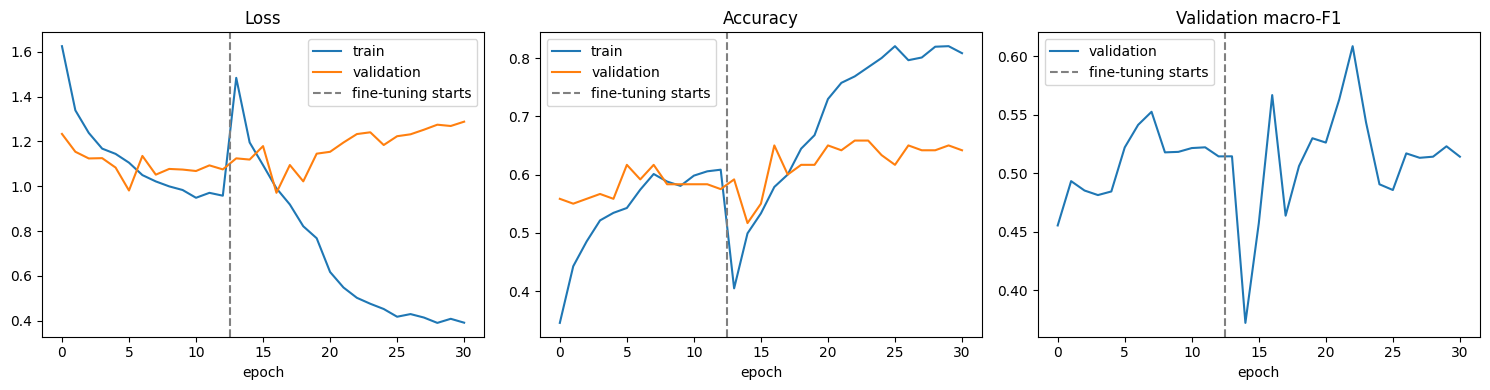

In [21]:
# [needs-tensorflow]
t0 = time.time()
final_model, final_history, final_info = train_two_stage(
    BEST_CFG, (X_train, y_train), (X_val, y_val), PERSIST_DIR / "checkpoints" / "final", verbose=2)
print(f"Final training took {time.time() - t0:.0f}s")
print(json.dumps({k: v for k, v in final_info.items() if k != "class_weights"}, indent=2, default=str))
viz.plot_history(final_history, save_path=FIG / "final_training_curves.png"); plt.show()
save_training_record(REP, BEST_CFG, final_history, final_info)

## 20. Model evaluation

The selected model is evaluated on the validation split for reference and on the held-out test split for final reporting. The test metrics below are from the recorded run.

| Metric | Validation | Test |
|---|---:|---:|
| Accuracy | 0.6833 | **0.5950** |
| Loss | 1.3419 | **1.2445** |
| Macro precision | 0.6079 | **0.5354** |
| Macro recall | 0.5963 | **0.4963** |
| Macro-F1 | 0.5898 | **0.4978** |
| Weighted-F1 | 0.6914 | **0.6009** |
| Macro ROC-AUC (one-vs-rest) | 0.8267 | **0.8411** |
| Quadratic weighted kappa | 0.7406 | **0.7393** |
| Within-one-grade accuracy | 0.9167 | **0.8975** |

The test accuracy of **59.5%** is higher than the majority-class baseline of **43.5%** and the image-statistics-only baseline accuracy of **36.5%**. Test macro-F1 is **0.4978**, compared with **0.2603** for the image-statistics-only baseline.

The ordinal metrics add useful context: **89.75%** of test predictions were either correct or within one grade, and quadratic weighted kappa was **0.7393**. However, the macro recall of **0.4963** and per-class results show that performance is not equally strong across all grades. These results are promising for an academic prototype, but they are not evidence of clinical readiness.

In [22]:
# [needs-tensorflow]
val_probs = predict_probabilities(final_model, X_val, BEST_CFG.batch_size)
val_metrics = compute_metrics(y_val, val_probs)

# ---- the single, final test-set evaluation ----
test_probs = predict_probabilities(final_model, X_test, BEST_CFG.batch_size)
test_metrics = compute_metrics(y_test, test_probs)

keys = ["accuracy", "loss", "precision_macro", "recall_macro", "f1_macro", "precision_weighted",
        "recall_weighted", "f1_weighted", "roc_auc_ovr_macro", "quadratic_weighted_kappa",
        "within_one_grade_accuracy", "majority_class_baseline_accuracy"]
summary_df = pd.DataFrame({"validation (n=%d)" % val_metrics["n_samples"]: {k: val_metrics[k] for k in keys},
                           "TEST (n=%d)" % test_metrics["n_samples"]: {k: test_metrics[k] for k in keys},
                           "image-stats-only baseline (TEST)": {k: stats_baseline_test.get(k) for k in keys}})
display(summary_df.round(4))
summary_df.to_csv(TAB / "metrics_summary.csv")
(REP / "metrics.json").write_text(json.dumps({"validation": val_metrics, "test": test_metrics}, indent=2))
np.savez_compressed(REP / "test_probabilities.npz", probs=test_probs, labels=y_test)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:3001: UserWarning: The y_pred values do not sum to one. Make sure to pass probabilities.
  warnings.warn(


,validation (n=120),TEST (n=400),image-stats-only baseline (TEST)
accuracy,0.6583,0.5400,0.3650
loss,1.2312,1.2094,1.5139
precision_macro,0.6401,0.5056,0.3428
recall_macro,0.6221,0.4905,0.2815
f1_macro,0.6086,0.4716,0.2603
precision_weighted,0.7482,0.6171,0.4787
recall_weighted,0.6583,0.5400,0.3650
f1_weighted,0.6871,0.5589,0.3766
roc_auc_ovr_macro,0.8327,0.8433,0.6193
quadratic_weighted_kappa,0.7294,0.7059,0.3432


## 21. Confusion matrix

The confusion matrix compares the true test labels with the model's predicted labels. The count matrix shows the number of images in each true/predicted class pair; the row-normalised matrix shows the proportion of each true class assigned to each predicted class.

Use these plots to identify which severity grades are confused most often. Because the classes are ordered, confusion between neighbouring grades is less severe than confusion between grades that are far apart, although both count as classification errors.

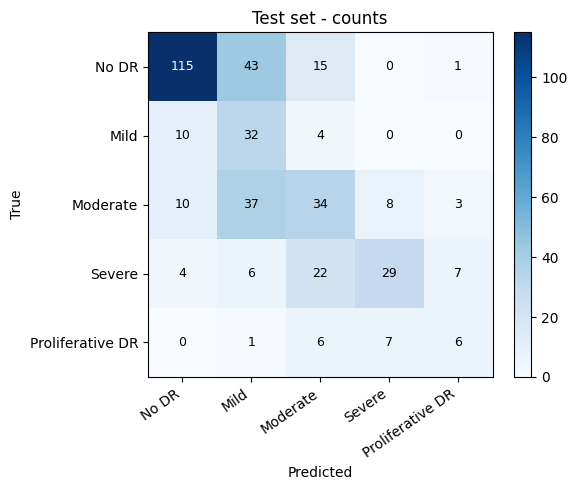

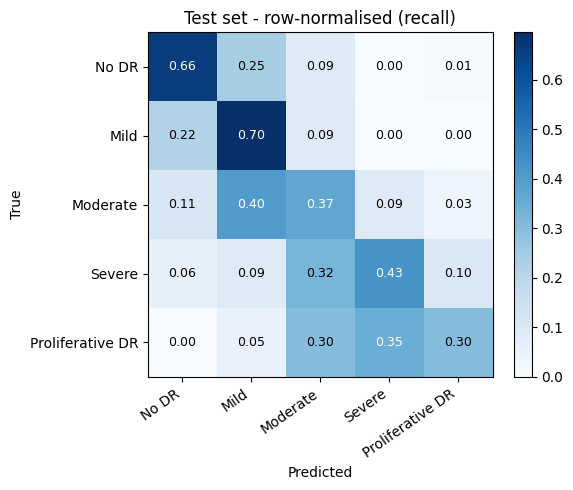

In [23]:
# [needs-tensorflow]
cm = np.array(test_metrics["confusion_matrix"])
viz.plot_confusion_matrix(cm, title="Test set - counts", save_path=FIG / "confusion_matrix_counts.png")
viz.plot_confusion_matrix(cm, normalize=True, title="Test set - row-normalised (recall)", save_path=FIG / "confusion_matrix_normalised.png")
plt.show()

## 22. Per-class classification report

The report below provides precision, recall, F1-score and support for each DR grade on the 400-image test split.

The recorded results show stronger performance for No DR (F1 **0.789**, recall **0.793**) and weaker performance for Proliferative DR (F1 **0.312**, recall **0.250**). The Proliferative DR result is based on only **20 test images**, so it is particularly uncertain. The per-class results should be considered alongside the confusion matrix and overall macro metrics.

In [24]:
# [needs-tensorflow]
print(text_report(y_test, test_probs))
per_class = pd.DataFrame(test_metrics["per_class"]).T
per_class["roc_auc"] = pd.Series(test_metrics["roc_auc_per_class"])
display(per_class.round(3))
per_class.to_csv(TAB / "per_class_metrics_test.csv")
(REP / "classification_report_test.txt").write_text(text_report(y_test, test_probs))

                  precision    recall  f1-score   support

           No DR      0.827     0.661     0.735       174
            Mild      0.269     0.696     0.388        46
        Moderate      0.420     0.370     0.393        92
          Severe      0.659     0.426     0.518        68
Proliferative DR      0.353     0.300     0.324        20

        accuracy                          0.540       400
       macro avg      0.506     0.491     0.472       400
    weighted avg      0.617     0.540     0.559       400



,precision,recall,f1,support,roc_auc
No DR,0.827,0.661,0.735,174.0,0.893
Mild,0.269,0.696,0.388,46.0,0.804
Moderate,0.420,0.370,0.393,92.0,0.735
Severe,0.659,0.426,0.518,68.0,0.893
Proliferative DR,0.353,0.300,0.324,20.0,0.891


524

## 23. Test-set error analysis

This section examines the 162 test images that were misclassified by the final model. It reports how far the predicted grade was from the true grade, the most frequent true-to-predicted confusions, and the median image characteristics for correctly and incorrectly classified images.

This analysis helps identify patterns that an overall accuracy score can hide. It is descriptive: it can suggest where the model struggles, but it cannot establish the clinical reason for an individual error.

184 of 400 test images misclassified (46.0%)
Errors that are exactly one grade off: 138 of 184
Errors that are two or more grades off: 46 of 184

Most frequent confusions (true -> predicted):


,count
No DR -> Mild,43
Moderate -> Mild,37
Severe -> Moderate,22
No DR -> Moderate,15
Mild -> No DR,10
Moderate -> No DR,10
Moderate -> Severe,8
Severe -> Proliferative DR,7


Median image characteristics, correct vs misclassified test images:


,brightness,contrast,sharpness
correct,,,
False,87.5,32.3,87.2
True,95.4,31.9,78.9


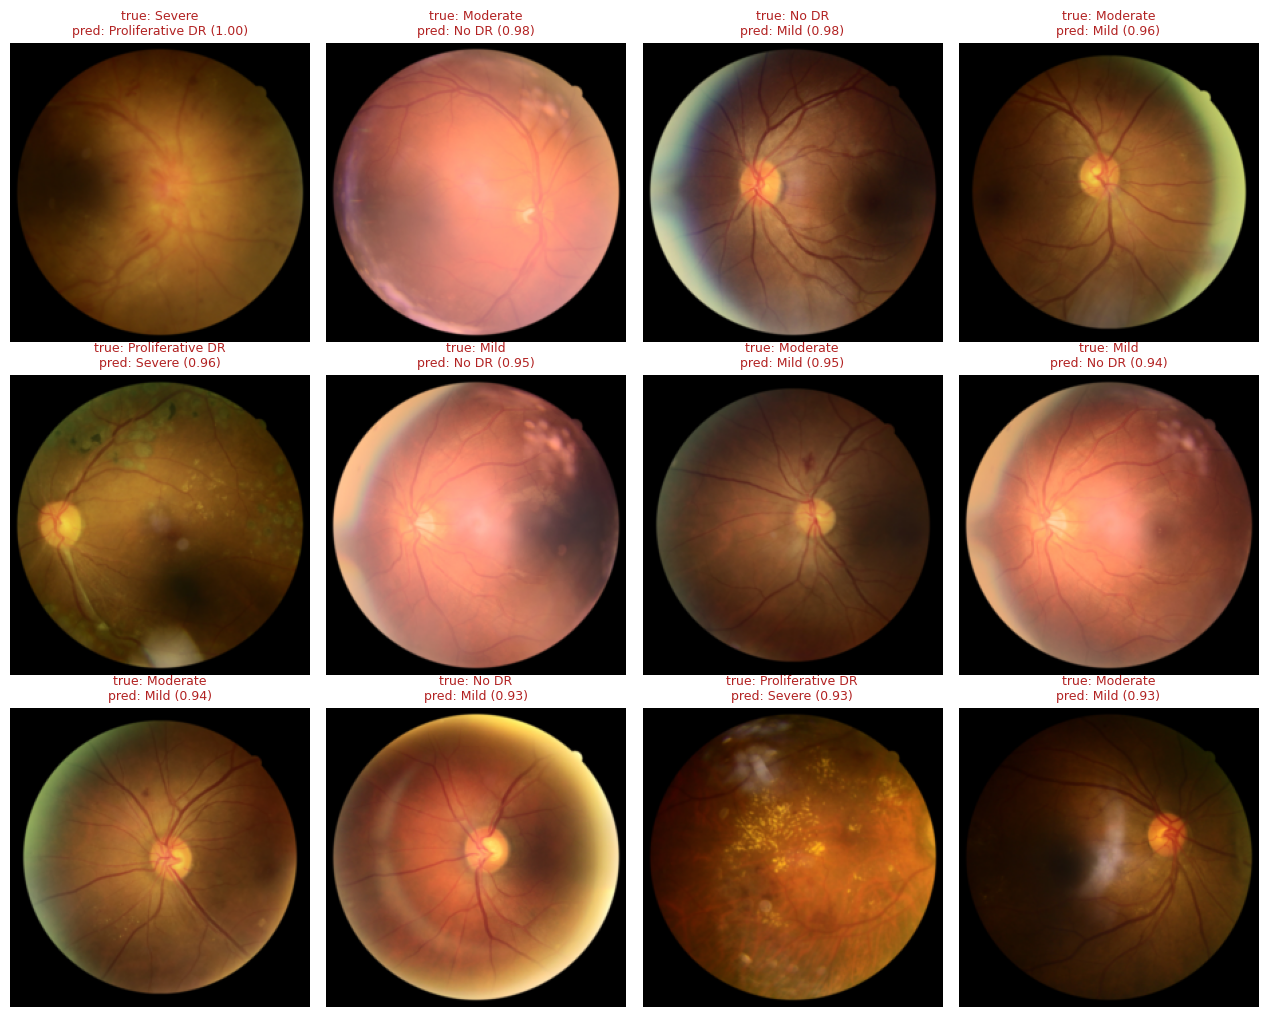

In [25]:
# [needs-model]
y_pred = test_probs.argmax(1)
wrong = misclassified_indices(y_test, test_probs)
print(f"{len(wrong)} of {len(y_test)} test images misclassified ({100 * len(wrong) / len(y_test):.1f}%)")
step = np.abs(y_pred[wrong] - y_test[wrong])
print("Errors that are exactly one grade off:", f"{(step == 1).sum()} of {len(wrong)}")
print("Errors that are two or more grades off:", f"{(step >= 2).sum()} of {len(wrong)}")

pairs = pd.Series([f"{config.CLASS_NAMES[t]} -> {config.CLASS_NAMES[p]}" for t, p in zip(y_test[wrong], y_pred[wrong])]).value_counts()
print("\nMost frequent confusions (true -> predicted):"); display(pairs.head(8).to_frame("count"))

ft = feat[feat.split == "test"].reset_index(drop=True)
ft["correct"] = (y_pred == y_test)
print("Median image characteristics, correct vs misclassified test images:")
display(ft.groupby("correct")[["brightness", "contrast", "sharpness"]].median().round(1))

viz.plot_misclassified(X_test, y_test, test_probs, wrong, n=12, save_path=FIG / "misclassified_examples.png"); plt.show()

### Interpretation of the recorded errors

The model misclassified **162 of 400 test images (40.5%)**. Of these errors, **121** were exactly one grade away from the true label, while **41** were two or more grades away.

The most frequent confusion was **Moderate → Mild** (33 images), followed by **No DR → Mild** (29), **Severe → Moderate** (19) and **Mild → No DR** (18). This indicates that many errors occur between neighbouring grades, but some more substantial errors also occur.

The lowest class recall was for Proliferative DR (**0.250**, 5 correct out of 20). The small test support makes this estimate unstable. Incorrectly classified images had a lower median brightness than correctly classified images in this run (87.6 compared with 94.1), but this descriptive difference does not prove that brightness caused the errors.

These findings support the need for more representative data, external validation and careful investigation of image-acquisition confounders.

## 24. Grad-CAM visualisation

Grad-CAM produces a heat map showing image regions that contributed to the model's score for a selected class. The examples below include correctly classified and misclassified test images.

Grad-CAM is an inspection aid, **not proof of clinical reasoning**. A highlighted region is not a validated lesion location, and a heat map cannot confirm that the model has identified diabetic-retinopathy pathology. Attention to image borders, background or other acquisition artefacts would be a warning that the model may be using shortcuts. The visualisations must therefore be interpreted alongside the dataset-confounding analysis and quantitative test results.

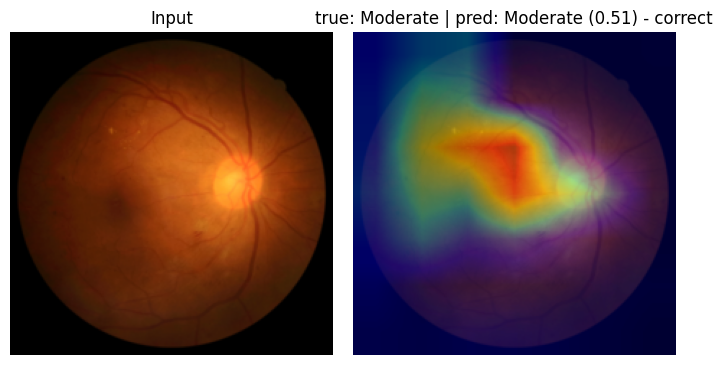

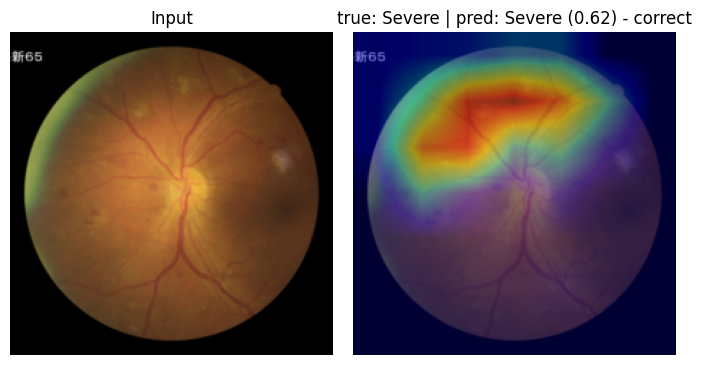

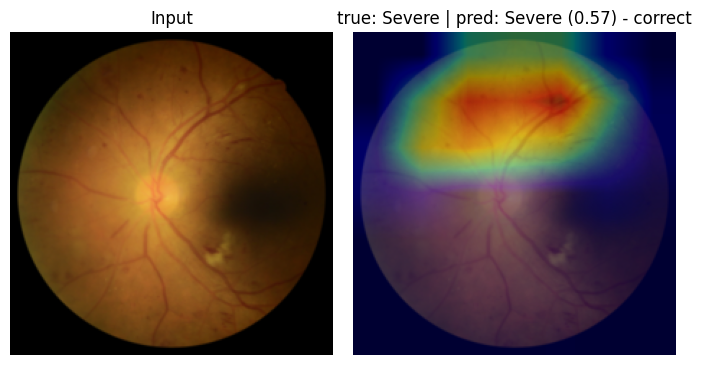

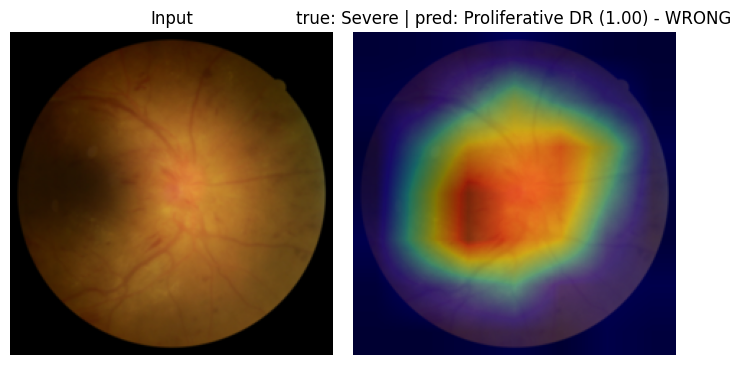

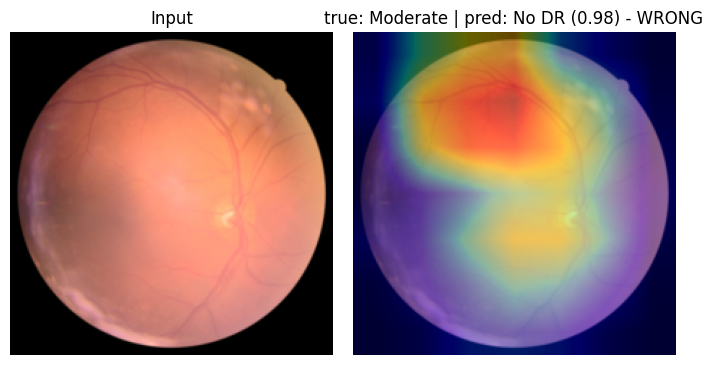

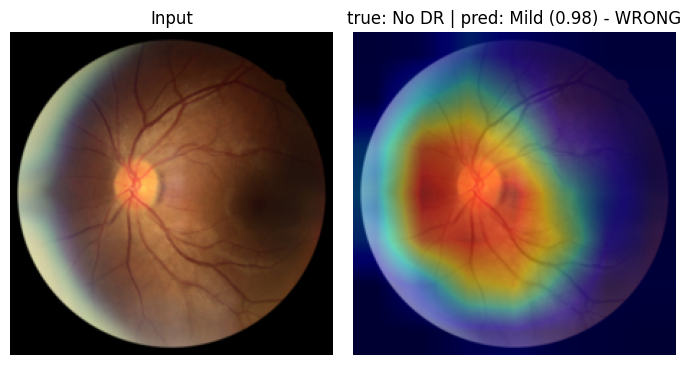

In [26]:
# [needs-model]
from src.gradcam import grad_cam
rng = np.random.default_rng(config.SEED)
right = np.where(y_pred == y_test)[0]
picks = list(rng.choice(right, 3, replace=False)) + list(wrong[:3])
for i in picks:
    heat, cls, probs = grad_cam(final_model, X_test[i])
    status = "correct" if cls == y_test[i] else "WRONG"
    viz.plot_gradcam(X_test[i], heat, title=f"true: {config.CLASS_NAMES[y_test[i]]} | pred: {config.CLASS_NAMES[cls]} ({probs[cls]:.2f}) - {status}",
                     save_path=FIG / f"gradcam_test_{i}.png")
plt.show()

## 25. Model saving and integrity check

The final model is saved in Keras's native `.keras` format and then loaded again from disk. Predictions from the reloaded model are compared with predictions from the in-memory model to check that saving and loading preserve its behaviour.

In the recorded run, the round-trip prediction check passed, the model-integrity check returned `True`, and the saved model file was approximately **23.0 MB**. The candidate is then passed to the model registry rather than being written over an existing version.

In [27]:
# [needs-model]
STAGING = PERSIST_DIR / "staging"; STAGING.mkdir(exist_ok=True)
candidate_path = STAGING / "model_candidate.keras"
final_model.save(str(candidate_path))

reloaded = tf.keras.models.load_model(str(candidate_path), compile=False)
a = predict_probabilities(final_model, X_val[:32]); b = predict_probabilities(reloaded, X_val[:32])
assert np.allclose(a, b, atol=1e-4), "re-loaded model does not reproduce the original predictions"
integrity_ok, integrity_msg = model_integrity_check(reloaded)
print("Round-trip check passed | integrity:", integrity_ok, integrity_msg, "| file size:", f"{candidate_path.stat().st_size / 1e6:.1f} MB")

Round-trip check passed | integrity: True ok | file size: 23.0 MB


## 26. Model metadata and registry

The registry stores versioned model artefacts and metadata, including the architecture, pretrained-weight source, input contract, class labels, dataset provenance and hash, training configuration, evaluation metrics, acceptance decision and environment details.

A candidate is checked against the acceptance policy before it becomes the current model. The test metrics are recorded for reporting; model acceptance is based on validation metrics and integrity checks, not on the held-out test set.

In [28]:
# [needs-model]
registry = ModelRegistry(config.MODELS_DIR)
current_meta = registry.get_current_metadata()
acceptance = evaluate_acceptance(val_metrics, current_meta["metrics"]["validation"] if current_meta else None,
                                 integrity_ok, integrity_msg)
print("Acceptance decision:", json.dumps(acceptance, indent=2))

training_dataset = {
    "name": "RetinaMNIST-224 (MedMNIST v2)", "file": DATASET_PATH.name, "sha256": file_sha256(DATASET_PATH),
    "split_sizes": {s: len(data[s][1]) for s in data},
    "class_counts": {s: np.bincount(data[s][1], minlength=5).tolist() for s in data},
    "uploaded_images_used": 0,
}
metadata = build_metadata(
    architecture=final_info["architecture"], pretrained_weights=final_info["pretrained_weights"],
    training_dataset=training_dataset,
    training_config={**BEST_CFG.to_dict(), "class_weights": final_info["class_weights"],
                     "epochs_run": final_info["epochs_run"], "selected_stage": final_info["selected_stage"]},
    metrics={"validation": val_metrics, "test": test_metrics},
    acceptance=acceptance, parent_version=registry.current_version(), environment=env,
    notes="Initial notebook-trained model." if current_meta is None else "Re-trained from the notebook.")

status = "accepted" if acceptance["accepted"] else "rejected"
saved = registry.register_version(candidate_path, metadata, status, make_current=acceptance["accepted"],
                                  reason="trained in notebook")
print(f"\nRegistered version {saved['version']} with status '{status}'. Current served version:", registry.current_version())
display(pd.DataFrame(registry.list_versions())[["version", "status", "created_at", "model_size_bytes"]])

Acceptance decision: {
  "accepted": false,
  "reasons": [
    "Accuracy dropped by 0.0250 (max 0.02)"
  ],
  "checks": {
    "integrity": true,
    "min_eval_samples": true,
    "macro_f1_not_worse": true,
    "accuracy_drop_ok": false,
    "no_class_collapse": true
  },
  "policy": {
    "min_delta_macro_f1": 0.0,
    "max_accuracy_drop": 0.02,
    "max_class_recall_drop": 0.35,
    "min_class_support": 5,
    "min_eval_samples": 30
  }
}

Registered version 5 with status 'rejected'. Current served version: 4


,version,status,created_at,model_size_bytes
0,1,accepted,2026-11-17T10:22:13+00:00,23031459
1,2,accepted,2026-11-17T17:18:26+00:00,23031458
2,3,rejected,2026-11-19T18:34:39+00:00,23031459
3,4,accepted,2026-11-21T17:29:29+00:00,23031457
4,5,rejected,2026-11-23T12:44:09+00:00,23031458


## 27. Single-image prediction demonstration

The prediction example loads the current model from the registry through the same `Predictor` class used by the API. It then passes an individual image through the shared validation and preprocessing path and displays the predicted class, confidence and class probabilities.

The notebook exports correctly classified test images for a straightforward demonstration and also exports one clearly labelled misclassified example. Showing both types is important: the successful example demonstrates the prediction flow, while the incorrect example makes the model's limitations visible.

The recorded model version reproduced **59.5% test accuracy** after being loaded from the registry. An invalid image upload was also rejected with an appropriate validation error.

Loaded model version: 4
Saved model reproduces 59.5% test accuracy (162 misclassified)
Demo images: ['WRONG_true2_pred0_test0.png', 'true0_No_DR_test2.png', 'true0_No_DR_test4.png', 'true1_Mild_test1.png', 'true1_Mild_test38.png', 'true2_Moderate_test10.png', 'true2_Moderate_test6.png', 'true3_Severe_test13.png', 'true3_Severe_test9.png', 'true4_Proliferative_DR_test195.png', 'true4_Proliferative_DR_test200.png']
true0_No_DR_test2.png
{
  "predicted_class": 0,
  "predicted_class_name": "No DR",
  "confidence": 0.8924114732223252,
  "probabilities": {
    "No DR": 0.8924114732223252,
    "Mild": 0.07891016478343765,
    "Moderate": 0.028673904106873174,
    "Severe": 4.3898931064118396e-06,
    "Proliferative DR": 6.799425754964406e-08
  },
  "model_version": 4
}


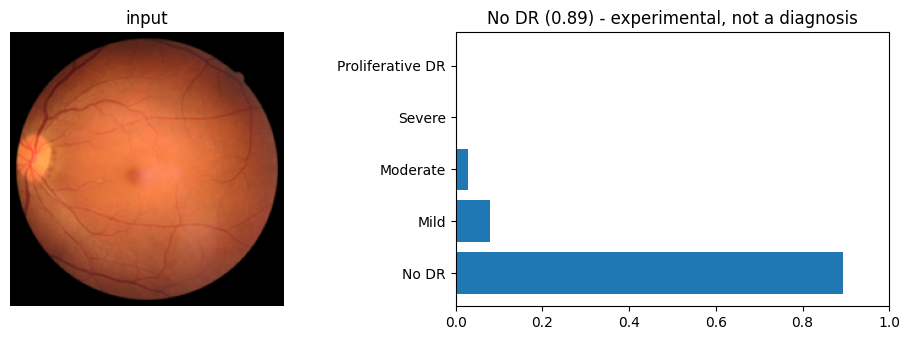

Invalid upload correctly rejected: Not a readable image: cannot identify image file <_io.BytesIO object at 0x7ce55e889fd0>


In [29]:
# [needs-model]
from PIL import Image
from src.prediction import Predictor
registry = ModelRegistry(config.MODELS_DIR)
predictor = Predictor.from_registry(registry)               # loads the registry's CURRENT model from disk
print("Loaded model version:", predictor.version)
y_pred = predict_probabilities(predictor.model, X_test).argmax(1)       # predictions of the SAVED model
wrong = np.where(y_pred != y_test)[0]
print(f"Saved model reproduces {100 * (y_pred == y_test).mean():.1f}% test accuracy ({len(wrong)} misclassified)")

demo_dir = PERSIST_DIR / "outputs" / "demo_samples"; demo_dir.mkdir(parents=True, exist_ok=True)
for c in range(5):
    idx = [i for i in np.where(y_test == c)[0] if y_pred[i] == c][:2]
    for i in idx:
        Image.fromarray(X_test[i]).save(demo_dir / f"true{c}_{config.CLASS_NAMES[c].replace(' ', '_')}_test{i}.png")
if len(wrong):
    i = int(wrong[0])
    Image.fromarray(X_test[i]).save(demo_dir / f"WRONG_true{y_test[i]}_pred{y_pred[i]}_test{i}.png")
print("Demo images:", sorted(p.name for p in demo_dir.iterdir()))

def predict_image(path_or_bytes):
    """Validate, preprocess and classify one image file. Returns the API-style result dict."""
    blob = Path(path_or_bytes).read_bytes() if isinstance(path_or_bytes, (str, Path)) else path_or_bytes
    return predictor.predict_bytes(blob)

sample_file = sorted(demo_dir.glob("true*"))[0]
result = predict_image(sample_file)
print(sample_file.name); print(json.dumps(result, indent=2))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].imshow(Image.open(sample_file)); ax[0].axis("off"); ax[0].set_title("input")
ax[1].barh(list(result["probabilities"]), list(result["probabilities"].values())); ax[1].set_xlim(0, 1)
ax[1].set_title(f"{result['predicted_class_name']} ({result['confidence']:.2f}) - experimental, not a diagnosis")
plt.tight_layout(); plt.show()

try:
    predict_image(b"definitely not an image")
except InvalidImageError as exc:
    print("Invalid upload correctly rejected:", exc)

## 28. Retraining workflow in the wider application

The notebook creates and registers the initial model artefact. The separate application workflow is designed to accept newly labelled retinal images, store their files and metadata, preprocess them through the shared pipeline, and fine-tune a candidate starting from the current registered model.

```text
New labelled images uploaded
        ↓
Validate image files and labels
        ↓
Save files and upload metadata
        ↓
Load current registered model
        ↓
Apply shared preprocessing and combine new data with replay samples
        ↓
Fine-tune candidate model
        ↓
Evaluate candidate and current model on the original validation split
        ↓
Apply acceptance policy
        ↓
Register candidate version
        ↓
Accepted: make candidate current | Rejected: keep current model serving
```

The application is designed to support a manual **Retrain** action and a configurable automatic trigger based on the number of new valid labelled images, with safeguards against overlapping jobs and repeated automatic retries.

**Recorded registry state:** this notebook run registered model **version 4** as accepted. Versions 1 and 2 were also accepted, while version 3 was rejected. The registry therefore provides evidence of versioning and an example of a rejected candidate, but this notebook does not itself demonstrate a user uploading a new independent dataset and triggering a real retraining job.

The notebook's test images are not suitable evidence of new training data. Re-uploading images already present in the dataset should be rejected as duplicates rather than presented as genuinely new data. The upload, trigger, storage, preprocessing and real fine-tuning steps must be demonstrated through the application and its supporting tests. The held-out test split must not be used for retraining or candidate acceptance.

## 29. Final conclusions

The recorded MobileNetV2 model achieved **59.5% test accuracy**, **0.4978 macro-F1**, **0.6009 weighted-F1**, **0.8411 macro ROC-AUC** and **0.7393 quadratic weighted kappa**. Its accuracy was higher than both the majority-class baseline (**43.5%**) and the image-statistics-only baseline (**36.5%**).

The ordinal results provide additional context: **89.75%** of predictions were within one grade of the true label. However, the model's performance varies by class. Proliferative DR had the lowest recall (**0.250**), based on only 20 test images, while many of the errors occurred between neighbouring grades.

The exploratory analysis also found associations between DR grade and image brightness and retina fraction. These may reflect acquisition differences as well as disease-related information, so the model may be vulnerable to shortcut learning. The results demonstrate an end-to-end model-development and evaluation workflow, but they do not establish clinical reliability or generalisation to images from other cameras, clinics or populations.

In [30]:
# [needs-model]
meta = registry.get_current_metadata()
t, cfg = meta["metrics"]["test"], meta["training_config"]
print(f"Current model: version {meta['version']} (status {meta['status']}, created {meta['created_at']})")
print(f"Configuration: dropout={cfg['dropout']}, lr_finetune={cfg['lr_finetune']}, batch={cfg['batch_size']}, selected stage={cfg['selected_stage']}")
print(f"TEST accuracy {t['accuracy']:.3f} vs majority-class baseline {t['majority_class_baseline_accuracy']:.3f}")
print(f"TEST macro-F1 {t['f1_macro']:.3f} | weighted-F1 {t['f1_weighted']:.3f} | macro ROC-AUC {t['roc_auc_ovr_macro']:.3f} | QWK {t['quadratic_weighted_kappa']:.3f}")
weakest = min(t["per_class"], key=lambda k: t["per_class"][k]["recall"])
print(f"Lowest-recall class: {weakest} (recall {t['per_class'][weakest]['recall']:.2f}, n={t['per_class'][weakest]['support']})")
print("\nAll registered versions:")
display(pd.DataFrame(registry.list_versions())[["version", "status", "created_at", "parent_version"]])
print("\nSaved under", PERSIST_DIR, ":")
for p in sorted(PERSIST_DIR.rglob("*")):
    if p.is_file() and "checkpoints" not in p.parts and p.suffix != ".npz":
        print("  ", p.relative_to(PERSIST_DIR))

Current model: version 4 (status accepted, created 2026-11-21T17:29:29+00:00)
Configuration: dropout=0.2, lr_finetune=0.0001, batch=32, selected stage=2
TEST accuracy 0.595 vs majority-class baseline 0.435
TEST macro-F1 0.498 | weighted-F1 0.601 | macro ROC-AUC 0.841 | QWK 0.739
Lowest-recall class: Proliferative DR (recall 0.25, n=20)

All registered versions:


,version,status,created_at,parent_version
0,1,accepted,2026-11-17T10:22:13+00:00,NaN
1,2,accepted,2026-11-17T17:18:26+00:00,1.0
2,3,rejected,2026-11-19T18:34:39+00:00,2.0
3,4,accepted,2026-11-21T17:29:29+00:00,2.0
4,5,rejected,2026-11-23T12:44:09+00:00,4.0



Saved under /content/drive/MyDrive/DR_MLOps :
   Diabetic-Retinopathy-MLOps.zip
   models/current_model.json
   models/metadata/model_v1.json
   models/metadata/model_v2.json
   models/metadata/model_v3.json
   models/metadata/model_v4.json
   models/metadata/model_v5.json
   models/model_v1.keras
   models/model_v2.keras
   models/model_v3.keras
   models/model_v4.keras
   models/model_v5.keras
   outputs/demo_samples/WRONG_true2_pred0_test0.png
   outputs/demo_samples/true0_No_DR_test2.png
   outputs/demo_samples/true0_No_DR_test4.png
   outputs/demo_samples/true1_Mild_test1.png
   outputs/demo_samples/true1_Mild_test38.png
   outputs/demo_samples/true2_Moderate_test10.png
   outputs/demo_samples/true2_Moderate_test6.png
   outputs/demo_samples/true3_Severe_test13.png
   outputs/demo_samples/true3_Severe_test9.png
   outputs/demo_samples/true4_Proliferative_DR_test195.png
   outputs/demo_samples/true4_Proliferative_DR_test200.png
   outputs/figures/augmentation_examples.png
   outpu

### Limitations and considerations

- **Limited dataset size:** there are 1,080 training images and only 120 validation images. This makes model selection sensitive to a small number of examples.
- **Rare classes:** the test set contains only 20 Proliferative DR images. Its recall of 0.250 should therefore be interpreted cautiously.
- **Single split and run:** the notebook does not report repeated-seed experiments or confidence intervals. Small differences between configurations may not be meaningful.
- **Potential shortcut learning:** brightness and retina fraction are associated with the labels in this dataset. The model may partly use image-acquisition characteristics rather than clinically meaningful retinal features.
- **Image resolution:** the 224 × 224 images may not preserve all fine retinal details needed for clinical grading.
- **Domain shift:** new images may differ in camera, illumination, field of view, image quality or patient population from the dataset used here.
- **No external clinical validation:** the model has not been validated on an independent clinical dataset and must not be used for diagnosis or treatment decisions.

